# Problems Assessment Notebook

In [14]:
# Importing Libraries

# Mathematics library
import math

# Permutations and combinations
import itertools

# Random selections
import random

# For numerical arrays
import numpy as np

# For plotting
import matplotlib.pyplot as plt

# For data manipulation
import pandas as pd

In [15]:
# Load the iris dataset from a CSV file
iris_data = pd.read_csv('iris.csv')

# Show the first 5 rows
iris_data.head(5)

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [16]:
# Show the last 5 rows
iris_data.tail(5)

,sepal.length,sepal.width,petal.length,petal.width,variety
145,6.7,3.0,5.2,2.3,Virginica
146,6.3,2.5,5.0,1.9,Virginica
147,6.5,3.0,5.2,2.0,Virginica
148,6.2,3.4,5.4,2.3,Virginica
149,5.9,3.0,5.1,1.8,Virginica


## Problem 1: Exploring Petal Length

The Iris dataset contains measurements of 150 iris flowers belonging to three species: setosa, versicolor, and virginica. For each flower, the dataset records sepal length, sepal width, petal length, and petal width.

Using the Iris dataset, investigate the distribution of petal_length.

 - Plot a histogram showing the petal lengths of all 150 flowers.

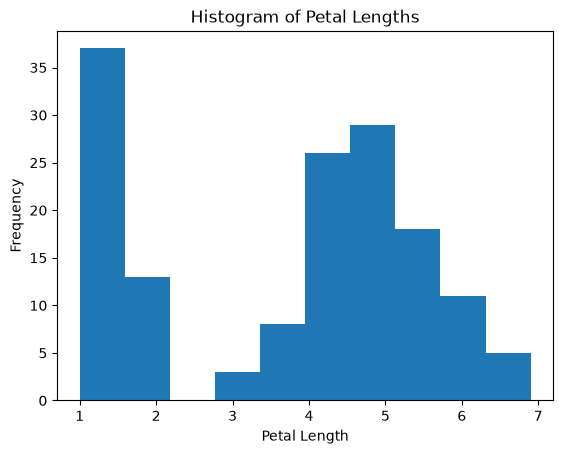

In [17]:
# Histogram showing the petal lengths of all flowers

plt.hist(iris_data['petal.length'])
plt.xlabel('Petal Length')
plt.ylabel('Frequency')
plt.title('Histogram of Petal Lengths')

plt.show()


 - On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data.

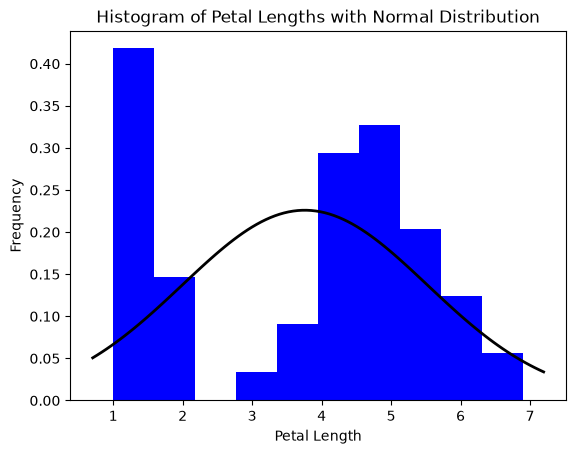

In [29]:
# Adding a normal distribution on the histogram

mean = iris_data['petal.length'].mean()
std = iris_data['petal.length'].std()

plt.hist(iris_data['petal.length'], bins=10, density=True, color='blue')

xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = (1 / (std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mean) / std) ** 2)
plt.plot(x, p, 'k', linewidth=2)

plt.xlabel('Petal Length')
plt.ylabel('Frequency')
plt.title('Histogram of Petal Lengths with Normal Distribution')

plt.show()

 - Histograms for each of the three species, and superimpose an appropriate normal distribution on each.

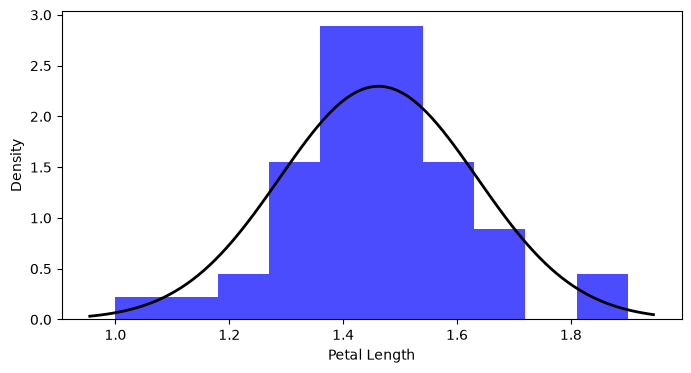

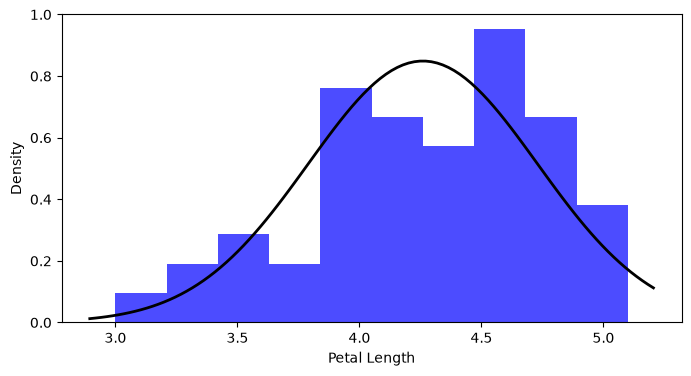

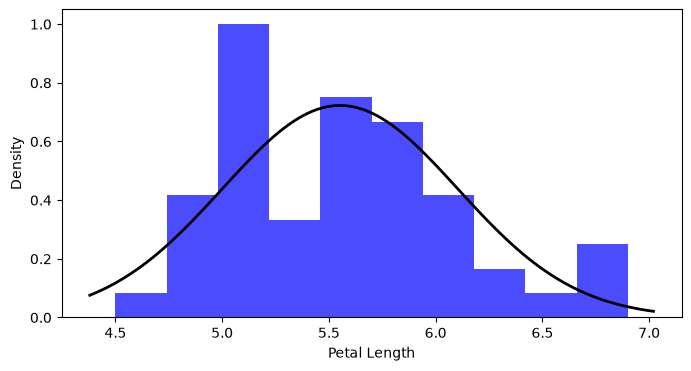

In [31]:

# Histogram for each species, with the normal distribution on each
species_list = iris_data['variety'].unique()

for species in species_list:
    species_data = iris_data[iris_data['variety'] == species]

    mean = species_data['petal.length'].mean()
    std = species_data['petal.length'].std()

    # Separate figure for each species
    plt.figure(figsize=(8, 4))

    plt.hist(species_data['petal.length'], bins=10, density=True, color='b', alpha=0.7)

    xmin, xmax = plt.xlim()
    x = np.linspace(xmin, xmax, 100)

    p = (1 / (std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mean) / std) ** 2)
    plt.plot(x, p, 'k', linewidth=2)

    plt.xlabel('Petal Length')
    plt.ylabel('Density')

    plt.show()

 - Mean and standard deviation of petal length for the complete dataset

In [33]:
# Mean and Standard Deviation for petal length
mean_petal_length = iris_data['petal.length'].mean()
std_petal_length = iris_data['petal.length'].std()

print("Mean Petal Length:", mean_petal_length)
print("Standard Deviation Petal Length:", std_petal_length)

Mean Petal Length: 3.7580000000000005
Standard Deviation Petal Length: 1.7652982332594662


 - Mean and STD for each species 

In [35]:
# Mean and Standard Deviation for petal length by species
species_list = iris_data['variety'].unique()

for species in species_list:
    species_data = iris_data[iris_data['variety'] == species]
    mean = species_data['petal.length'].mean()
    std = species_data['petal.length'].std()
    print(f"{species} - Mean Petal Length: {mean}, Standard Deviation: {std}")

Setosa - Mean Petal Length: 1.4620000000000002, Standard Deviation: 0.17366399648018407
Versicolor - Mean Petal Length: 4.26, Standard Deviation: 0.46991097723995795
Virginica - Mean Petal Length: 5.5520000000000005, Standard Deviation: 0.5518946956639834


 - Describe and compare the distributions you observe. In particular, discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.

## Problem 2: Correlation Between Petal Length and Petal Width

Investigate the relationship between petal_length and petal_width in the Iris dataset.
1. Calculate the Pearson correlation coefficient between petal length and petal width using all 150 flowers.
2. Create an appropriate scatter plot showing the relationship between the two variables, and include a suitable line to help illustrate the relationship.
3. Calculate the Pearson correlation coefficient separately for each of the three species.
4. Create an appropriate plot showing the relationship between petal length and petal width for each species.
5. Report and compare the correlation coefficients.
6. Explain what the correlation coefficients tell you about the relationship between petal length and petal width, both for the dataset as a whole and within each species.

## Problem 3: Comparing Species Using t-Tests

Investigate whether the three iris species differ in their petal_length and petal_width.

For each pair of species:

 - setosa vs versicolor
 - setosa vs virginica
 - versicolor vs virginica

perform an independent-samples t-test for:

 - petal length,
 - petal width.

For each test:

1. State the null and alternative hypotheses.
2. Calculate the t-statistic and p-value using scipy.stats.
3. Use a significance level of α=0.05 to decide whether to reject the null hypothesis.
4. Summarise your results in an appropriate table.
5. Explain what the results tell you about differences between the three species.

## Problem 4: Comparing the Species Using ANOVA

The t-tests in Problem 3 require several separate comparisons between species. Instead, investigate differences in petal length and petal width using one-way analysis of variance (ANOVA).

For each variable:

1. State the null and alternative hypotheses for a one-way ANOVA.
2. Perform a one-way ANOVA comparing the three species using scipy.stats.
3. Report the F-statistic and p-value.
4. Use a significance level of α=0.05 to determine whether there is evidence that the species have different population means.
5. Explain what the ANOVA result tells you and what it does not tell you about the individual species.

The t-tests in Problem 3 involved three pairwise comparisons. Explain why performing several separate hypothesis tests can increase the overall probability of making a type I error, and explain how ANOVA addresses this problem by testing the three group means simultaneously.

Finally, compare the conclusions from your t-tests with those from the ANOVA and explain why ANOVA is generally preferable when comparing more than two groups.

## End